# 23 · Actuators: motor, position, velocity, general gain/bias, and the Panda's servos

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt

JOINT = """<mujoco><option timestep="0.002"><flag contact="disable" gravity="disable"/></option>
<worldbody><body><joint name="j" axis="0 0 1" damping="0.1"/>
<geom type="capsule" fromto="0 0 0 .4 0 0" size=".03" mass="1"/></body></worldbody>
<actuator>{act}</actuator></mujoco>"""

def step_response(act_xml, ctrl, T=1.5):
    m = mujoco.MjModel.from_xml_string(JOINT.format(act=act_xml)); d = mujoco.MjData(m)
    q, f = [], []
    while d.time < T:
        d.ctrl[0] = ctrl
        mujoco.mj_step(m, d)
        q.append(d.qpos[0]); f.append(d.actuator_force[0])
    t = np.arange(len(q)) * m.opt.timestep
    return t, np.array(q), np.array(f), m

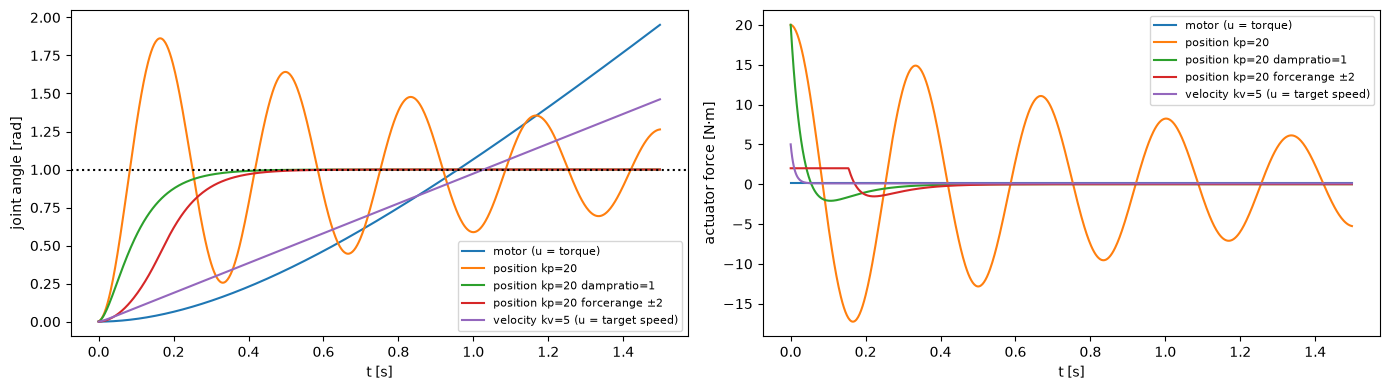

In [2]:
acts = {
    "motor (u = torque)": ('<motor joint="j" ctrlrange="-1 1"/>', 0.2),
    "position kp=20": ('<position joint="j" kp="20"/>', 1.0),
    "position kp=20 dampratio=1": ('<position joint="j" kp="20" dampratio="1"/>', 1.0),
    "position kp=20 forcerange ±2": ('<position joint="j" kp="20" dampratio="1" forcelimited="true" forcerange="-2 2"/>', 1.0),
    "velocity kv=5 (u = target speed)": ('<velocity joint="j" kv="5"/>', 1.0),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, (xml, u) in acts.items():
    t, q, f, m = step_response(xml, u)
    axes[0].plot(t, q, label=name); axes[1].plot(t, f, label=name)
axes[0].axhline(1.0, c="k", ls=":"); axes[0].set_ylabel("joint angle [rad]"); axes[1].set_ylabel("actuator force [N·m]")
for a in axes:
    a.set_xlabel("t [s]"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [3]:
t, q, f, m = step_response('<position joint="j" kp="20" dampratio="1"/>', 1.0)
a = m.actuator(0)
print("gainprm[0] (a) =", a.gainprm[0], "| biasprm[:3] (b0, b1, b2) =", a.biasprm[:3].round(3))
print("force = a*u + b0 + b1*q + b2*qdot = kp*(u - q) - kv*qdot   -> a PD servo is a 'general' actuator")
b = a.biasprm[:3]
t2, q2, _, _ = step_response(f'<general joint="j" gainprm="{a.gainprm[0]}" biasprm="{b[0]} {b[1]} {b[2]}" biastype="affine"/>', 1.0)
print("general actuator reproduces position servo:", np.allclose(q2, q, atol=1e-2))

gainprm[0] (a) = 20.0 | biasprm[:3] (b0, b1, b2) = [  0.    -20.     -2.124]
force = a*u + b0 + b1*q + b2*qdot = kp*(u - q) - kv*qdot   -> a PD servo is a 'general' actuator
general actuator reproduces position servo: True


In [4]:
panda = mm.load("franka_emika_panda")
for i in range(panda.nu):
    a = panda.actuator(i)
    print(f"{a.name:10s} trntype={mujoco.mjtTrn(panda.actuator_trntype[i]).name:12s} kp={a.gainprm[0]:7.1f} "
          f"bias={a.biasprm[:3].round(1)} ctrlrange={a.ctrlrange.round(2)} forcerange={a.forcerange.round(1)}")

actuator1  trntype=mjTRN_JOINT  kp= 4500.0 bias=[    0. -4500.  -450.] ctrlrange=[-2.9  2.9] forcerange=[-87.  87.]
actuator2  trntype=mjTRN_JOINT  kp= 4500.0 bias=[    0. -4500.  -450.] ctrlrange=[-1.76  1.76] forcerange=[-87.  87.]
actuator3  trntype=mjTRN_JOINT  kp= 3500.0 bias=[    0. -3500.  -350.] ctrlrange=[-2.9  2.9] forcerange=[-87.  87.]
actuator4  trntype=mjTRN_JOINT  kp= 3500.0 bias=[    0. -3500.  -350.] ctrlrange=[-3.07 -0.07] forcerange=[-87.  87.]
actuator5  trntype=mjTRN_JOINT  kp= 2000.0 bias=[    0. -2000.  -200.] ctrlrange=[-2.9  2.9] forcerange=[-12.  12.]
actuator6  trntype=mjTRN_JOINT  kp= 2000.0 bias=[    0. -2000.  -200.] ctrlrange=[-0.02  3.75] forcerange=[-12.  12.]
actuator7  trntype=mjTRN_JOINT  kp= 2000.0 bias=[    0. -2000.  -200.] ctrlrange=[-2.9  2.9] forcerange=[-12.  12.]
actuator8  trntype=mjTRN_TENDON kp=    0.0 bias=[   0. -100.  -10.] ctrlrange=[  0. 255.] forcerange=[-100.  100.]


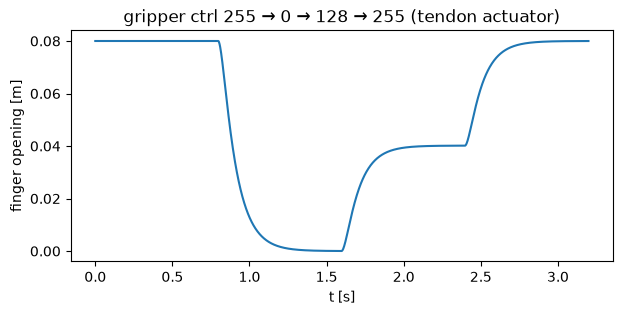

In [5]:
d = mujoco.MjData(panda)
mujoco.mj_resetDataKeyframe(panda, d, 0)
widths = []
for u in [255, 0, 128, 255]:
    for _ in range(400):
        d.ctrl[7] = u; mujoco.mj_step(panda, d)
        widths.append(d.qpos[7] + d.qpos[8])
plt.figure(figsize=(7, 3)); plt.plot(np.arange(len(widths)) * panda.opt.timestep, widths)
plt.ylabel("finger opening [m]"); plt.xlabel("t [s]"); plt.title("gripper ctrl 255 → 0 → 128 → 255 (tendon actuator)"); plt.show()